# CC3092 · Laboratorio #8 — Series de tiempo y forecasting

## 0. Instalación, reproducibilidad y presupuesto computacional

In [2]:
%pip -q install "holidays>=0.60" "statsforecast>=2.0" "neuralforecast>=3.0" "lightgbm>=4.0" "chronos-forecasting>=2.0" "pyarrow>=15" "seaborn>=0.13"

In [3]:
import os, gc, io, json, math, random, time, warnings, urllib.request, zipfile
from pathlib import Path
from copy import deepcopy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import holidays
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, Subset
from IPython.display import display

SEED = 2026
N_CLIENTES = 100  # mínimo del PDF, exactamente los mismos en todos los modelos
L, H = 168, 24
QUICK_MODE = False  # True para depurar; False para la ejecución académica
RUN_NEURALFORECAST = True
RUN_CHRONOS = True
RUN_AUTOETS = True
RUN_EXTENDED = True  # sensibilidad, 3 semillas, local/global, monthly refits, H=168
EXPORT_DIR = Path('/content/resultados_lab8' if Path('/content').exists() else './resultados_lab8')
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
MAX_TRAIN_SAMPLES = 8000 if QUICK_MODE else 30000  # submuestreo de ventanas, no de clientes
MAX_VALID_SAMPLES = 3000 if QUICK_MODE else 8000
EPOCHS = 2 if QUICK_MODE else 10
NF_STEPS = 20 if QUICK_MODE else 250
BATCH_SIZE = 256
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()
print(f'PyTorch={torch.__version__} | dispositivo={DEVICE} | GPU={torch.cuda.get_device_name(0) if torch.cuda.is_available() else "sin GPU"}')
print('Perfil:', 'DEPURACIÓN' if QUICK_MODE else 'ACADÉMICO', '| mínimo 100 clientes constante')

PyTorch=2.11.0+cu130 | dispositivo=cuda | GPU=Tesla T4
Perfil: ACADÉMICO | mínimo 100 clientes constante


## 1. Descarga, conversión física y selección de clientes
**Conversión correcta** (documentación oficial UCI): cada medida representa kW promediados durante 15 minutos; 1 intervalo aporta kWh = kW × 0.25. Así, para cada hora se suman las cuatro lecturas y **se divide entre 4**. Los ceros en clientes activados después de 2011 no son valores perdidos; se filtran clientes activos durante el primer día de 2012. Esto aproxima el requisito «datos completos desde 2012-01-01» sin asumir que todo cero sea dato faltante.

**Cambio de horario:** UCI preservó 96 registros por día, incluso en las fechas DST: en marzo puso ceros en la hora omitida; en octubre concentró dos horas reales en un bloque. Se mantiene esa convención original de **24 horas civiles etiquetadas por día** para que los 92 días de prueba tengan H=24. No aplicar `tz_localize` ni interpolar la hora de marzo, pues modificaría la definición del dataset. Se marcan explícitamente ambos días cada año como anomalías estructurales.

In [4]:
URL = 'https://archive.ics.uci.edu/static/public/321/electricityloaddiagrams20112014.zip'
ROOT = Path('/content' if Path('/content').exists() else '.')
ZIP_FILE = ROOT/'electricity.zip'; DATA_FILE = ROOT/'LD2011_2014.txt'
if not DATA_FILE.exists():
    if not ZIP_FILE.exists():
        print('Descargando dataset UCI (≈250 MB)...')
        urllib.request.urlretrieve(URL, ZIP_FILE)
    with zipfile.ZipFile(ZIP_FILE) as z:
        candidates = [x for x in z.namelist() if x.endswith('LD2011_2014.txt') and not x.startswith('__MACOSX')]
        assert len(candidates) == 1, 'Archivo LD2011_2014.txt no encontrado en ZIP'
        print('Extrayendo archivo de ≈678 MB...')
        with z.open(candidates[0]) as src, open(DATA_FILE, 'wb') as dst:
            import shutil; shutil.copyfileobj(src, dst)

raw = pd.read_csv(DATA_FILE, sep=';', decimal=',', index_col=0, parse_dates=True, dtype=np.float32)
raw.index = pd.to_datetime(raw.index)
raw = raw.sort_index()
assert raw.index.is_unique, 'Investigar marcas de tiempo repetidas'
print('Datos originales (cuartos de hora × clientes):', raw.shape)

first_day = raw.loc['2012-01-01 00:00:00':'2012-01-01 23:45:00']
active = first_day.columns[(first_day.fillna(0).gt(0).any(axis=0)) & raw.notna().all(axis=0)]
assert len(active) >= N_CLIENTES, f'Solo {len(active)} clientes elegibles: revisar la regla'
rng = np.random.default_rng(SEED)
clientes = sorted(rng.choice(active.to_numpy(), size=N_CLIENTES, replace=False).tolist())
print('Clientes activos y sin NaN:', len(active), '| clientes elegidos:', len(clientes))
print('Primeros clientes:', clientes[:8])

# El promedio de potencia en la hora × duración de 1h equivale a sumar kW/4.
hourly = (raw[clientes].resample('h').sum(min_count=4) / 4.0).astype(np.float32)
hourly = hourly.loc['2012-01-01 00:00:00':'2014-12-31 23:00:00']
expected_idx = pd.date_range('2012-01-01', '2014-12-31 23:00:00', freq='h')
assert hourly.index.equals(expected_idx), 'Se detectaron horas faltantes o adicionales'
assert hourly.notna().all().all(), 'Hay NaN horarios que exigen análisis'
assert (hourly.to_numpy() >= 0).all(), 'Existen consumos negativos'
del raw; gc.collect()
print('Panel horario:', hourly.shape, '| observaciones en panel:', hourly.size)
print('Horas por cliente:', len(hourly), '| consumo kWh (promedio global):', round(hourly.to_numpy().mean(), 4))

Descargando dataset UCI (≈250 MB)...
Extrayendo archivo de ≈678 MB...
Datos originales (cuartos de hora × clientes): (140256, 370)
Clientes activos y sin NaN: 320 | clientes elegidos: 100
Primeros clientes: ['MT_002', 'MT_004', 'MT_006', 'MT_021', 'MT_027', 'MT_028', 'MT_036', 'MT_040']
Panel horario: (26304, 100) | observaciones en panel: 2630400
Horas por cliente: 26304 | consumo kWh (promedio global): 898.0347


In [5]:
# Las transiciones son el último domingo de marzo/octubre cada año (Portugal continental).
def last_sunday(year, month):
    end = pd.Timestamp(year, month, 1) + pd.offsets.MonthEnd(0)
    return end - pd.Timedelta(days=(end.weekday()+1)%7)
dst_days = [(y, str(last_sunday(y, 3).date()), str(last_sunday(y, 10).date())) for y in (2012, 2013, 2014)]
print('Año / salto primavera / cambio otoño:')
for row in dst_days: print(row)
# No recuperamos energía horaria real en el bloque doble de octubre: limitación explícita.

Año / salto primavera / cambio otoño:
(2012, '2012-03-25', '2012-10-28')
(2013, '2013-03-31', '2013-10-27')
(2014, '2014-03-30', '2014-10-26')


## 2. EDA, feriados y covariables conocidas a futuro
Codificamos hora, día de la semana y mes con seno/coseno y feriado con un indicador binario (Portugal). No se usan consumos futuros observados como entrada.

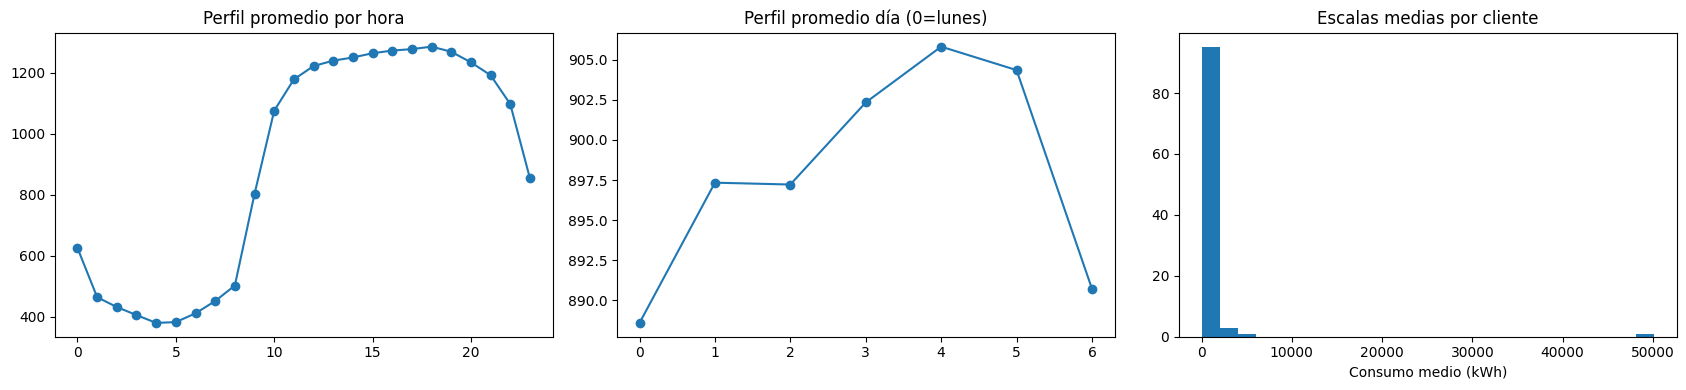

Escala media de consumo por cliente (kWh): {'min': 2.459451675415039, 'median': 159.49635314941406, 'max': 50132.25390625}
Promedio diario global de los feriados seleccionados:


,kWh_h_promedio
2012-01-01,552.931091
2012-12-25,546.639648
2013-01-01,523.471924
2013-12-25,492.037354
2014-01-01,507.366608
2014-12-25,439.501251


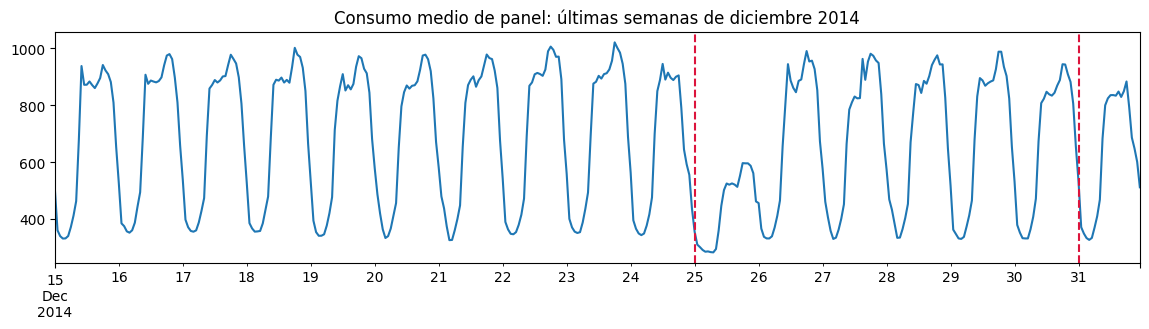

In [6]:
pt_holidays = holidays.country_holidays('PT', years=[2012, 2013, 2014])
calendar = pd.DataFrame(index=hourly.index)
calendar['hour'] = calendar.index.hour.astype(int)
calendar['weekday'] = calendar.index.dayofweek.astype(int)
calendar['month'] = calendar.index.month.astype(int)
calendar['holiday'] = np.fromiter((int(ts.date() in pt_holidays) for ts in calendar.index), dtype=np.int8)
for name, period, base in [('hour',24,0), ('weekday',7,0), ('month',12,1)]:
    angle = 2*np.pi*(calendar[name].to_numpy()-base)/period
    calendar[f'{name}_sin'] = np.sin(angle).astype('float32')
    calendar[f'{name}_cos'] = np.cos(angle).astype('float32')
CAL_COLS = ['hour_sin','hour_cos','weekday_sin','weekday_cos','month_sin','month_cos','holiday']
cal_np = calendar[CAL_COLS].to_numpy(dtype=np.float32)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
mean_agg = hourly.mean(axis=1)
mean_agg.groupby(mean_agg.index.hour).mean().plot(ax=axes[0], marker='o', title='Perfil promedio por hora')
mean_agg.groupby(mean_agg.index.dayofweek).mean().plot(ax=axes[1], marker='o', title='Perfil promedio día (0=lunes)')
axes[2].hist(hourly.mean(axis=0).to_numpy(), bins=25)
axes[2].set(title='Escalas medias por cliente', xlabel='Consumo medio (kWh)')
plt.tight_layout(); plt.show()
scales = hourly.mean(axis=0)
print('Escala media de consumo por cliente (kWh):', scales.agg(['min','median','max']).to_dict())
# Día de Navidad y Año Nuevo vs resto de diciembre/enero.
special = mean_agg.loc[mean_agg.index.normalize().isin([
    pd.Timestamp(f'{y}-{m:02d}-{d:02d}') for y in (2012,2013,2014) for m,d in [(1,1),(12,25)]
])]
print('Promedio diario global de los feriados seleccionados:')
display(special.resample('D').mean().dropna().to_frame('kWh_h_promedio'))
ax = mean_agg.loc['2014-12-15':'2014-12-31'].plot(figsize=(14,3), title='Consumo medio de panel: últimas semanas de diciembre 2014')
for day in ['2014-12-25', '2014-12-31']: ax.axvline(pd.Timestamp(day), ls='--', color='crimson')
plt.show()

## 3. Partición temporal, normalización y Dataset de ventanas
Estandarización **por serie** usando exclusivamente el bloque de entrenamiento, con media y desviación estándar por cliente. La misma transformación se reutiliza en validación y prueba; la inversión devuelve kWh. El denominador MASE usa la diferencia estacional de 168 h **calculada solo en entrenamiento**. El contexto de validación/prueba puede extenderse al bloque temporal precedente (ya observado); solo el **objetivo** de cada ventana debe caer íntegramente dentro de su bloque.

In [7]:
idx = hourly.index
T0 = idx.get_loc(pd.Timestamp('2012-01-01 00:00:00'))
T_TR = idx.get_loc(pd.Timestamp('2014-07-01 00:00:00'))
T_VA = idx.get_loc(pd.Timestamp('2014-10-01 00:00:00'))
T_END = len(idx)
Y = hourly.to_numpy(dtype=np.float32).T.copy()  # [n_clientes, n_horas]
MEAN = Y[:, T0:T_TR].mean(axis=1).astype(np.float32)
STD = Y[:, T0:T_TR].std(axis=1).astype(np.float32)
STD = np.maximum(STD, 1e-3)
Z = ((Y - MEAN[:,None])/STD[:,None]).astype(np.float32)
# Escala estacional: denominador distinto por serie; 168h de rezago.
MASE_DEN = np.mean(np.abs(Y[:,168:T_TR] - Y[:,:T_TR-168]), axis=1)
MASE_DEN = np.where(MASE_DEN > 1e-8, MASE_DEN, np.nan)
assert np.isfinite(Z).all()
assert T_END-T_VA == 92*24
splits = {'train':(T0,T_TR), 'val':(T_TR,T_VA), 'test':(T_VA,T_END)}
print('Bloques (horas):', {k:b-a for k,(a,b) in splits.items()})

class SlidingPanelDataset(Dataset):
    """X: (L, 1+n_cal), y: (H,), future_calendar: (H,n_cal).
    El orden es serie > origen; n_ventanas=series*n_orígenes.
    """
    def __init__(self, which='train', lookback=168, horizon=24, stride=1, series_ids=None):
        self.lookback, self.horizon, self.which = lookback, horizon, which
        a,b = splits[which]
        self.origins = np.arange(max(a,lookback), b-horizon+1, stride, dtype=np.int32)
        self.series_ids = np.arange(len(clientes)) if series_ids is None else np.asarray(series_ids)
    def __len__(self): return len(self.series_ids)*len(self.origins)
    def __getitem__(self, item):
        nw = len(self.origins)
        ci, origin = int(self.series_ids[item//nw]), int(self.origins[item%nw])
        past = Z[ci, origin-self.lookback:origin,None]
        x = np.concatenate([past, cal_np[origin-self.lookback:origin]], axis=1)
        f = cal_np[origin:origin+self.horizon]
        target = Z[ci,origin:origin+self.horizon]
        return {'x':torch.from_numpy(x), 'future_cov':torch.from_numpy(f.copy()),
                'y':torch.from_numpy(target.copy()), 'client_idx':torch.tensor(ci, dtype=torch.long),
                'origin':torch.tensor(origin, dtype=torch.long)}

for split in ('train','val','test'):
    ds = SlidingPanelDataset(split,L,H,1)
    print(f'{split}: {len(ds):,} ventanas | {len(ds.origins):,} orígenes horarios × {len(clientes)} clientes')
example = SlidingPanelDataset('train')[0]
assert example['x'].shape == (L,1+len(CAL_COLS)) and example['y'].shape == (H,)
assert example['future_cov'].shape == (H,len(CAL_COLS))
print('Shape de una muestra:', {k:tuple(v.shape) for k,v in example.items()})

Bloques (horas): {'train': 21888, 'val': 2208, 'test': 2208}
train: 2,169,700 ventanas | 21,697 orígenes horarios × 100 clientes
val: 218,500 ventanas | 2,185 orígenes horarios × 100 clientes
test: 218,500 ventanas | 2,185 orígenes horarios × 100 clientes
Shape de una muestra: {'x': (168, 8), 'future_cov': (24, 7), 'y': (24,), 'client_idx': (), 'origin': ()}


### Auditoría explícita de las cuatro fugas
- **Split aleatorio de ventanas:** prohibido; los índices del *target* están contenidos enteramente en train/val/test.
- **Escalador sobre toda la serie:** prohibido; `MEAN`, `STD` y `MASE_DEN` se ajustan únicamente antes de 2014-07-01.
- **Early stopping con test:** prohibido; selección sobre las fechas de julio-septiembre exclusivamente.
- **Covariables desalineadas:** los valores futuros son únicamente calendario ya conocido; se prueba la correspondencia origen ↔ timestamp y la no superposición de target/contexto.

In [8]:
# Pruebas automatizadas (si una falla, NO continuar).
for name,(a,b) in splits.items():
    ds = SlidingPanelDataset(name, L, H, 1)
    assert ds.origins.min() >= a
    assert ds.origins.max()+H <= b
    assert ds.origins.min() >= L
    assert np.all(np.diff(ds.origins) == 1)
assert not np.shares_memory(Y[:,:T_TR],Y[:,T_VA:])
assert np.allclose(MEAN, Y[:,:T_TR].mean(axis=1))
assert np.allclose(STD, np.maximum(Y[:,:T_TR].std(axis=1),1e-3))
for o in [T_TR,T_VA,T_VA+24,T_END-H]:
    assert idx[o-1]+pd.Timedelta(hours=1)==idx[o]
    assert np.allclose(cal_np[o:o+H], calendar.iloc[o:o+H][CAL_COLS].to_numpy())
    assert len(set(calendar.iloc[o:o+H].index)) == H
print('4 auditorías de fuga: APROBADAS; test bloqueado para tuneo.')

4 auditorías de fuga: APROBADAS; test bloqueado para tuneo.


## 4. Métricas y backtesting común
**Una sola interfaz** `backtest(modelo, bloque)` evalúa cualquier predictor que implemente `predict(origin, horizon)` y produzca matriz `(n_clientes,H)` en **kWh**. En test se consideran exactamente 92 orígenes a las 00:00. Los modelos pueden consultar las horas previas a cada origen, nunca los objetivos del origen actual. El MAPE sobre y≈0 es inestable: se reporta NaN cuando y=0 y la fracción de ceros.

**MASE**: MAE de predicción dividido por MAE del naïve estacional de 168 horas **sobre entrenamiento** de cada cliente. **WAPE**: suma absoluta de errores / suma absoluta real de todo el panel, no media de WAPE por cliente.

In [9]:
def point_metrics(y_true, y_pred, mase_den=MASE_DEN):
    # ambas matrices [origen, cliente, horizonte]
    e = np.asarray(y_pred,dtype=np.float64)-np.asarray(y_true,dtype=np.float64)
    a = np.abs(e); yt = np.asarray(y_true,dtype=np.float64)
    den = mase_den[None,:,None]
    mask = np.abs(yt) > 1e-8
    mape = float(np.mean(100*a[mask]/np.abs(yt[mask]))) if mask.any() else np.nan
    return {'MAE':float(a.mean()), 'RMSE':float(np.sqrt(np.mean(e**2))),
            'WAPE':float(100*a.sum()/np.maximum(np.abs(yt).sum(),1e-10)),
            'MAPE':mape, 'MASE':float(np.nanmean(a/den)),
            'fraccion_ceros':float((~mask).mean())}

class ForecastResult:
    def __init__(self, name, origins, truth, pred, seconds, q10=None, q90=None):
        self.name,self.origins,self.y,self.pred,self.seconds = name,origins,truth,pred,seconds
        self.q10,self.q90 = q10,q90
    def metrics(self):
        d = point_metrics(self.y,self.pred)
        if self.q10 is not None and self.q90 is not None:
            d['pinball_P10_P90'] = float((pinball(self.y,self.q10,.1)+pinball(self.y,self.q90,.9))/2)
            d['cobertura_P10_P90'] = float(np.mean((self.y>=self.q10)&(self.y<=self.q90)))
        return d

def pinball(y, qhat, tau):
    delta=np.asarray(y)-np.asarray(qhat)
    return np.mean(np.maximum(tau*delta,(tau-1)*delta))

def daily_origins(which):
    a,b=splits[which]
    return np.arange(a,b-H+1,24,dtype=np.int32)

RESULTS = {}
VALIDATION = {}
MODEL_META = {}

def backtest(modelo, which='test', name=None, save=True, horizon=H):
    a,b=splits[which]
    origins=np.arange(a,b-horizon+1,24,dtype=np.int32)
    truth=np.stack([Y[:,o:o+horizon] for o in origins],axis=0)
    preds, lows, highs=[],[],[]
    t0=time.perf_counter()
    for o in origins:
        out=modelo.predict(int(o), horizon=horizon)
        if isinstance(out,tuple):
            p,qlo,qhi=out
            lows.append(np.asarray(qlo,dtype=np.float32)); highs.append(np.asarray(qhi,dtype=np.float32))
        else: p=out
        p=np.asarray(p,dtype=np.float32)
        if p.shape!=(len(clientes),horizon):
            raise ValueError(f'Predicción {name or modelo}: forma {p.shape} ≠ {(len(clientes),horizon)}')
        if not np.isfinite(p).all(): raise ValueError('El modelo produjo NaN/Inf')
        preds.append(p)
    elapsed=time.perf_counter()-t0
    res=ForecastResult(name or type(modelo).__name__,origins,truth,np.stack(preds),elapsed,
                       np.stack(lows) if lows else None,np.stack(highs) if highs else None)
    if save:
        (RESULTS if which=='test' else VALIDATION)[res.name]=res
    return res

class NaiveAdapter:
    def __init__(self, period=None):
        self.period=period
    def predict(self, origin, horizon=24):
        if self.period is None: return np.repeat(Y[:,origin-1:origin],horizon,axis=1)
        offset = np.arange(horizon)%self.period
        return Y[:,origin-self.period+offset]

# Implementación vectorizada matemáticamente idéntica a StatsForecast Naive/SeasonalNaive
# y adaptada al mismo protocolo sin reentrenar pesos.
baselines={
    'Naive':NaiveAdapter(),
    'SeasonalNaive24':NaiveAdapter(24),
    'SeasonalNaive168':NaiveAdapter(168),
}
for name, adapter in baselines.items():
    r=backtest(adapter,'val',name)
    print('VALIDACIÓN',name, r.metrics())
for name, adapter in baselines.items():
    r=backtest(adapter,'test',name)
    MODEL_META[name]={'familia':'Baseline/StatsForecast-equivalente','L':168 if '168' in name else 24,
                      'estrategia':'Regla fija','covariables':False,'parametros':0,'entrenables':0,
                      'entrenamiento_s':0.,'hardware':'CPU'}
    print('PRUEBA',name, r.metrics())

VALIDACIÓN Naive {'MAE': 586.1682525878642, 'RMSE': 4931.379135804396, 'WAPE': 51.02353882822352, 'MAPE': 43.19908384388074, 'MASE': 3.772670997490473, 'fraccion_ceros': 0.007155797101449275}
VALIDACIÓN SeasonalNaive24 {'MAE': 78.31989988376858, 'RMSE': 773.9653221198072, 'WAPE': 6.81742560280171, 'MAPE': 19.428072185798108, 'MASE': 0.9473751846591394, 'fraccion_ceros': 0.007155797101449275}
VALIDACIÓN SeasonalNaive168 {'MAE': 117.1255505509248, 'RMSE': 1327.3363656366294, 'WAPE': 10.195298107545268, 'MAPE': 14.713264492168198, 'MASE': 1.018129133883875, 'fraccion_ceros': 0.007155797101449275}
PRUEBA Naive {'MAE': 337.74612851609356, 'RMSE': 2789.965591659982, 'WAPE': 42.84507084816503, 'MAPE': 40.24072099913738, 'MASE': 3.310405923113772, 'fraccion_ceros': 0.014067028985507246}
PRUEBA SeasonalNaive24 {'MAE': 69.41020449096634, 'RMSE': 626.6065501127785, 'WAPE': 8.80509020804178, 'MAPE': 18.413510019993172, 'MASE': 1.0099195015715972, 'fraccion_ceros': 0.014067028985507246}
PRUEBA Seas